# Phase C: Selectivity Impact Analysis

This notebook generates the dual-axis scatter plots for each correlation level, plotting Latency and Recall against Selectivity (on a log scale). This allows us to visualize where recall collapse occurs and latency spikes.

In [1]:
import pandas as pd
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# Ensure output directories exist
os.makedirs('../outputs/plots', exist_ok=True)

# Load filters reference to get true selectivities
filters_path = '../outputs/filters_reference.json'
with open(filters_path, 'r') as f:
    filters_data = json.load(f)

selectivity_map = {f['filter_id']: f['actual'] for f in filters_data}
print(f"Loaded {len(selectivity_map)} filters.")

Loaded 44 filters.


In [2]:
# Load sweep results
results_path = '../outputs/sweep_results.jsonl'
records = []
with open(results_path, 'r') as f:
    for line in f:
        records.append(json.loads(line))

df = pd.DataFrame(records)
df['selectivity'] = df['filter_id'].map(selectivity_map)

print(f"Loaded {len(df)} sweep result records.")
df.head(2)

Loaded 1100 sweep result records.


,timestamp,filter_id,table_name,query_vector_idx,k,hnsw_ef_search,success,scan_strategy,index_used,planning_time_ms,latency_ms,filter_time_ms,rows_removed,recall,error_msg,recall_error,selectivity
0,2026-08-23T02:22:25.361953+00:00,f_000,hm_clothes_100,0,10,40,True,Bitmap Heap Scan,hm_clothes_100_product_type_name_idx,0.080,0.307,NaN,0,1.0,None,None,0.000124
1,2026-08-23T02:22:25.411242+00:00,f_001,hm_clothes_100,0,10,40,True,Bitmap Heap Scan,hm_clothes_100_product_type_name_idx,0.119,0.349,NaN,0,1.0,None,None,0.000143


In [3]:
# Aggregate metrics per table, filter, and selectivity
# - median latency avoids single-iteration spikes
# - min recall detects worst-case collapse scenario
agg_df = df.groupby(['table_name', 'filter_id', 'selectivity']).agg(
    median_latency_ms=('latency_ms', 'median'),
    min_recall=('recall', 'min')
).reset_index()

agg_df.head()

,table_name,filter_id,selectivity,median_latency_ms,min_recall
0,hm_clothes_0,f_000,0.000124,0.324,1.0
1,hm_clothes_0,f_001,0.000143,0.335,1.0
2,hm_clothes_0,f_002,0.000209,0.493,1.0
3,hm_clothes_0,f_003,0.000295,0.640,1.0
4,hm_clothes_0,f_004,0.000428,0.929,1.0


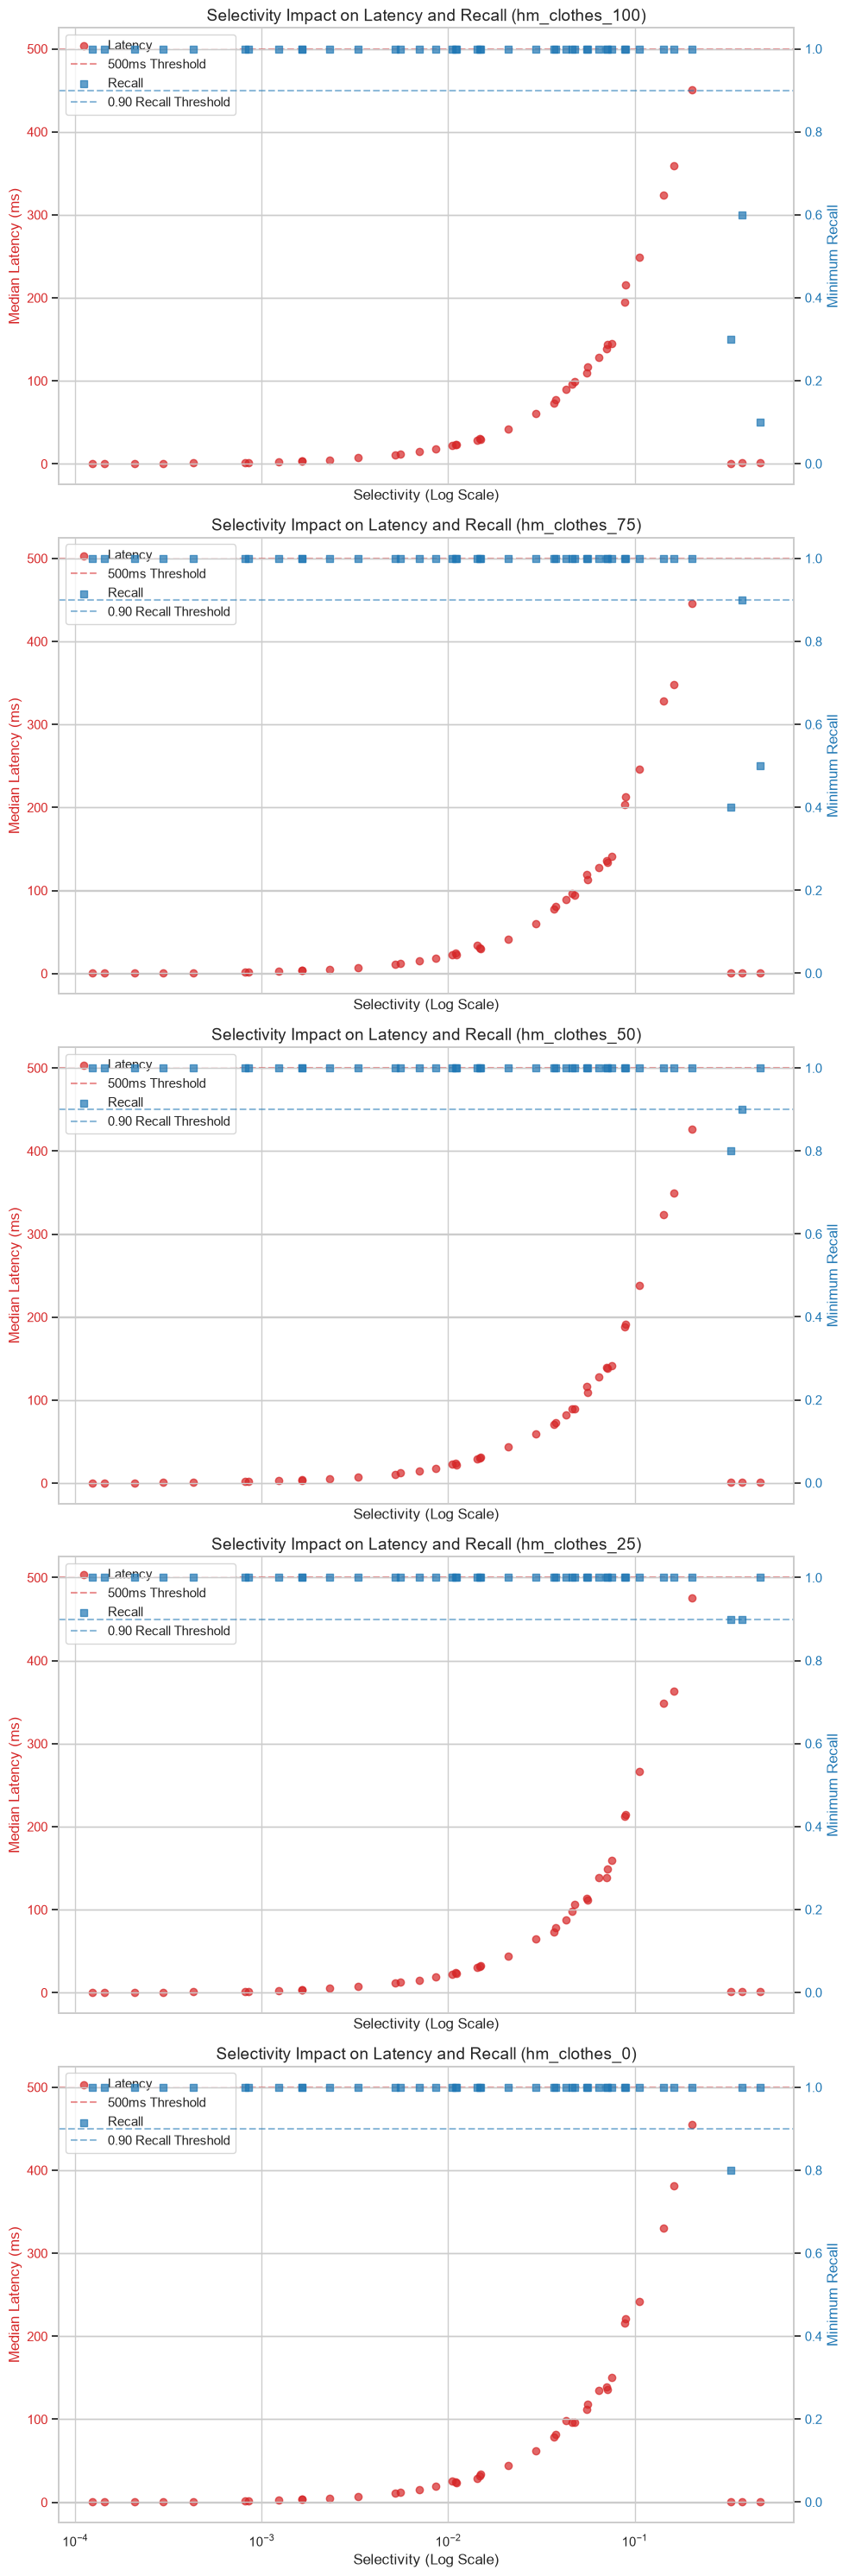

In [4]:
# Generate dual-axis scatter plots for each correlation level
table_names = ['hm_clothes_100', 'hm_clothes_75', 'hm_clothes_50', 'hm_clothes_25', 'hm_clothes_0']

fig, axes = plt.subplots(nrows=len(table_names), ncols=1, figsize=(10, 6 * len(table_names)), sharex=True)

for ax, table_name in zip(axes, table_names):
    table_data = agg_df[agg_df['table_name'] == table_name].copy()
    table_data = table_data.sort_values(by='selectivity')
    
    # --- Primary Y-Axis (Latency) ---
    color1 = 'tab:red'
    ax.set_xlabel('Selectivity (Log Scale)')
    ax.set_ylabel('Median Latency (ms)', color=color1)
    ax.scatter(table_data['selectivity'], table_data['median_latency_ms'], 
               color=color1, alpha=0.7, label='Latency')
    ax.tick_params(axis='y', labelcolor=color1)
    ax.set_xscale('log')
    ax.axhline(y=500, color=color1, linestyle='--', alpha=0.5, label='500ms Threshold')

    # --- Secondary Y-Axis (Recall) ---
    ax2 = ax.twinx()
    color2 = 'tab:blue'
    ax2.set_ylabel('Minimum Recall', color=color2)
    ax2.scatter(table_data['selectivity'], table_data['min_recall'], 
                color=color2, alpha=0.7, marker='s', label='Recall')
    ax2.tick_params(axis='y', labelcolor=color2)
    ax2.axhline(y=0.90, color=color2, linestyle='--', alpha=0.5, label='0.90 Recall Threshold')
    ax2.set_ylim(-0.05, 1.05)
    
    # Title and Legends
    ax.set_title(f'Selectivity Impact on Latency and Recall ({table_name})', fontsize=14)
    
    # Combine legends from both axes
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, loc='upper left')

plt.tight_layout()

# Save plot to outputs directory
plt.savefig('../outputs/plots/selectivity_impact_plots.png', dpi=300)
plt.show()